# Métodos Monte Carlo


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Generador reproducible para los ejemplos
rng = np.random.default_rng(2026)
plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True


## 1. Generación de números pseudoaleatorios
`default_rng` crea un generador. La semilla permite repetir una secuencia durante el desarrollo. La distribución debe corresponder al modelo físico o probabilístico que se quiere representar.

Media uniforme (aprox. 0.5): 0.4961013167848604
Media normal (aprox. 0): -0.015558463245899752
Frecuencia de éxito (aprox. 0.5): 0.495


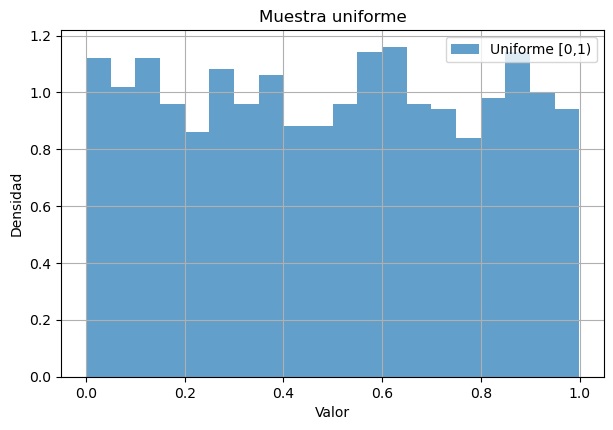

In [2]:
rng = np.random.default_rng(1234)
uniformes = rng.uniform(0, 1, size=1000)
normales = rng.normal(loc=0, scale=1, size=1000)
ensayos = rng.binomial(n=1, p=0.5, size=1000)

print("Media uniforme (aprox. 0.5):", uniformes.mean())
print("Media normal (aprox. 0):", normales.mean())
print("Frecuencia de éxito (aprox. 0.5):", ensayos.mean())
fig, ax = plt.subplots()
ax.hist(uniformes, bins=20, density=True, alpha=0.7, label="Uniforme [0,1)")
ax.set(xlabel="Valor", ylabel="Densidad", title="Muestra uniforme")
ax.legend(); plt.show()

## 2. Ejemplo resuelto 1: estimación de π por Monte Carlo
Generamos puntos uniformes en el cuadrado unitario. Un punto está dentro del cuarto de círculo si $x^2+y^2\leq 1$. La fracción de puntos dentro estima $\pi/4$.

Estimación de pi: 3.159200
Valor de referencia: 3.141593
Error absoluto: 0.017607
Error estándar estimado: 0.011524


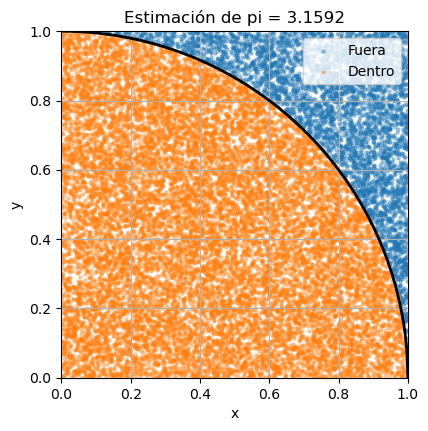

In [3]:
def estimar_pi(n, semilla=2026):
    """Estima pi mediante puntos uniformes en [0,1] x [0,1]."""
    generador = np.random.default_rng(semilla)
    x = generador.uniform(0, 1, n)
    y = generador.uniform(0, 1, n)
    dentro = x**2 + y**2 <= 1
    pi_estimado = 4 * dentro.mean()
    # Error estándar aproximado usando estimación Bernoulli de p
    p_hat = dentro.mean()
    se_pi = 4 * np.sqrt(p_hat * (1-p_hat) / n)
    return pi_estimado, se_pi, x, y, dentro

pi_hat, se_pi, x, y, dentro = estimar_pi(20_000, semilla=10)
print(f"Estimación de pi: {pi_hat:.6f}")
print(f"Valor de referencia: {np.pi:.6f}")
print(f"Error absoluto: {abs(pi_hat-np.pi):.6f}")
print(f"Error estándar estimado: {se_pi:.6f}")

fig, ax = plt.subplots()
ax.scatter(x[~dentro], y[~dentro], s=5, alpha=0.35, label="Fuera")
ax.scatter(x[dentro], y[dentro], s=5, alpha=0.35, label="Dentro")
t = np.linspace(0, 1, 300)
ax.plot(t, np.sqrt(1-t**2), color="black", lw=2)
ax.set(xlim=(0,1), ylim=(0,1), xlabel="x", ylabel="y", title=f"Estimación de pi = {pi_hat:.4f}")
ax.set_aspect("equal"); ax.legend(); plt.show()

### Convergencia con el tamaño de muestra
La estimación puede subir y bajar; buscamos una tendencia estadística, no una mejora monótona en cada paso.

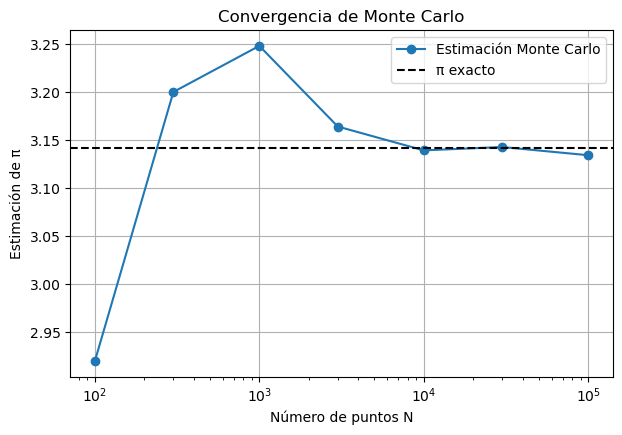

In [4]:
Ns = np.array([100, 300, 1_000, 3_000, 10_000, 30_000, 100_000])
estimaciones = []
for n in Ns:
    estimacion, _, _, _, _ = estimar_pi(int(n), semilla=2026 + int(n))
    estimaciones.append(estimacion)

fig, ax = plt.subplots()
ax.semilogx(Ns, estimaciones, "o-", label="Estimación Monte Carlo")
ax.axhline(np.pi, linestyle="--", color="black", label="π exacto")
ax.set(xlabel="Número de puntos N", ylabel="Estimación de π", title="Convergencia de Monte Carlo")
ax.legend(); plt.show()

## 3. Ejemplo resuelto 2: integración Monte Carlo
Estimamos $I=\int_0^1 e^{-x^2}\,dx$. Para muestras uniformes en $[0,1]$, el estimador es la media de $f(X_i)$. Su error estándar se estima con la desviación estándar muestral dividida por $\sqrt{N}$.

Monte Carlo: 0.74650552 +/- 0.00063562 (error estándar)
Cuadratura SciPy: 0.74682413
Error absoluto Monte Carlo: 0.00031861
Error estimado por quad: 8.29e-15


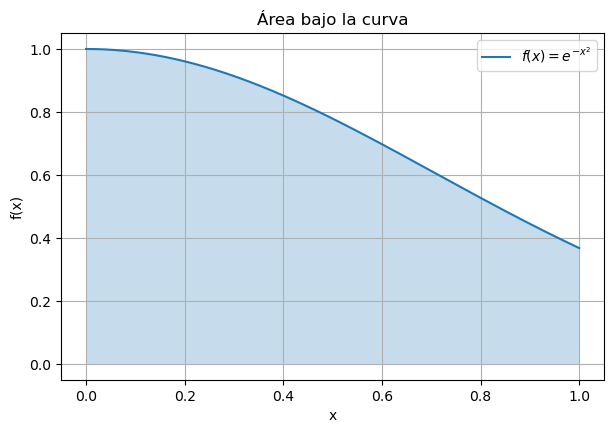

In [5]:
def integrar_mc(f, a, b, n, semilla=2026):
    """Estima integral de f en [a,b] y devuelve estimación y error estándar."""
    if n < 2:
        raise ValueError("n debe ser al menos 2 para estimar la desviación estándar")
    generador = np.random.default_rng(semilla)
    x = generador.uniform(a, b, n)
    fx = f(x)
    estimacion = (b-a) * np.mean(fx)
    error_estandar = (b-a) * np.std(fx, ddof=1) / np.sqrt(n)
    return estimacion, error_estandar

f = lambda x: np.exp(-x**2)
N = 100_000
I_mc, se_mc = integrar_mc(f, 0, 1, N, semilla=7)
I_ref, error_quad = quad(lambda x: np.exp(-x**2), 0, 1)
print(f"Monte Carlo: {I_mc:.8f} +/- {se_mc:.8f} (error estándar)")
print(f"Cuadratura SciPy: {I_ref:.8f}")
print(f"Error absoluto Monte Carlo: {abs(I_mc-I_ref):.8f}")
print(f"Error estimado por quad: {error_quad:.2e}")

xx = np.linspace(0, 1, 300)
fig, ax = plt.subplots()
ax.plot(xx, f(xx), label=r"$f(x)=e^{-x^2}$")
ax.fill_between(xx, 0, f(xx), alpha=0.25)
ax.set(xlabel="x", ylabel="f(x)", title="Área bajo la curva")
ax.legend(); plt.show()

### Estudiar el error al variar N
El error absoluto no tiene que decrecer monótonamente. Para observar la escala, es preferible repetir cada tamaño con varias semillas y analizar la distribución del error o el error RMS.

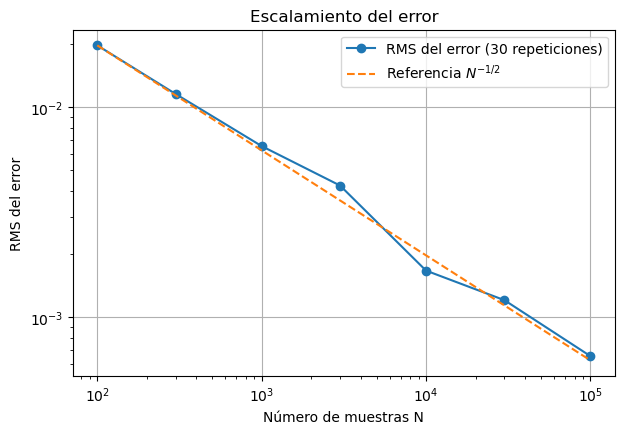

In [6]:
Ns = np.array([100, 300, 1_000, 3_000, 10_000, 30_000, 100_000])
repeticiones = 30
error_rms = []
for n in Ns:
    estimaciones_n = [integrar_mc(f, 0, 1, int(n), semilla=1000+j)[0]
                      for j in range(repeticiones)]
    error_rms.append(np.sqrt(np.mean((np.array(estimaciones_n)-I_ref)**2)))

fig, ax = plt.subplots()
ax.loglog(Ns, error_rms, "o-", label="RMS del error (30 repeticiones)")
# Referencia de pendiente N^(-1/2), reescalada para facilitar la comparación
referencia = error_rms[0] * np.sqrt(Ns[0] / Ns)
ax.loglog(Ns, referencia, "--", label=r"Referencia $N^{-1/2}$")
ax.set(xlabel="Número de muestras N", ylabel="RMS del error", title="Escalamiento del error")
ax.legend(); plt.show()

## 4. Simulación estocástica: ensayos de Bernoulli
Cada ensayo vale 1 con probabilidad $p$ y 0 con probabilidad $1-p$. La frecuencia observada estima $p$ y el error estándar aproximado es $\sqrt{\hat p(1-\hat p)/N}$.

In [7]:
rng = np.random.default_rng(15)
p_teorica = 0.5
Ns = [10, 100, 1_000, 10_000]
for n in Ns:
    muestra = rng.binomial(1, p_teorica, size=n)
    p_hat = muestra.mean()
    se = np.sqrt(p_hat * (1-p_hat) / n)
    print(f"N={n:>5}: frecuencia={p_hat:.4f}, error estándar aprox.={se:.4f}")

N=   10: frecuencia=0.5000, error estándar aprox.=0.1581
N=  100: frecuencia=0.4600, error estándar aprox.=0.0498
N= 1000: frecuencia=0.5140, error estándar aprox.=0.0158
N=10000: frecuencia=0.5093, error estándar aprox.=0.0050


## 5. Ejemplo resuelto: caminata aleatoria unidimensional
Cada paso es $+d$ o $-d$ con probabilidad 1/2. La posición final tiene media teórica cero y desplazamiento cuadrático medio teórico $Nd^2$.

Media del desplazamiento: 0.0400 (teoría: 0)
Desplazamiento cuadrático medio: 205.0760 (teoría: 200.0000)
RMS de la posición final: 14.3205 (teoría: 14.1421)


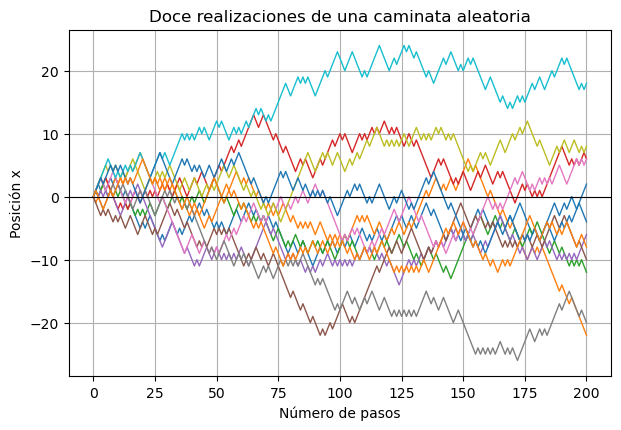

In [8]:
def simular_caminatas(n_particulas, n_pasos, d=1.0, semilla=2026):
    """Simula caminatas 1D. Devuelve posiciones de todas las trayectorias."""
    if n_particulas < 1 or n_pasos < 1:
        raise ValueError("n_particulas y n_pasos deben ser positivos")
    generador = np.random.default_rng(semilla)
    pasos = generador.choice([-d, d], size=(n_particulas, n_pasos))
    posiciones = np.concatenate([np.zeros((n_particulas, 1)), np.cumsum(pasos, axis=1)], axis=1)
    return posiciones

M, N, d = 2_000, 200, 1.0
pos = simular_caminatas(M, N, d=d, semilla=5)
finales = pos[:, -1]
media_sim = finales.mean()
msd_sim = np.mean(finales**2)
print(f"Media del desplazamiento: {media_sim:.4f} (teoría: 0)")
print(f"Desplazamiento cuadrático medio: {msd_sim:.4f} (teoría: {N*d**2:.4f})")
print(f"RMS de la posición final: {np.sqrt(msd_sim):.4f} (teoría: {d*np.sqrt(N):.4f})")

fig, ax = plt.subplots()
for i in range(12):
    ax.plot(np.arange(N+1), pos[i], lw=1)
ax.axhline(0, color="black", lw=0.8)
ax.set(xlabel="Número de pasos", ylabel="Posición x", title="Doce realizaciones de una caminata aleatoria")
plt.show()

### Comprobar la relación MSD = N d²
El desplazamiento cuadrático medio (mean squared displacement, MSD) se calcula promediando el cuadrado de las posiciones entre muchas partículas. La teoría predice $\langle x_N^2\rangle=Nd^2$ para una caminata simétrica con pasos independientes.

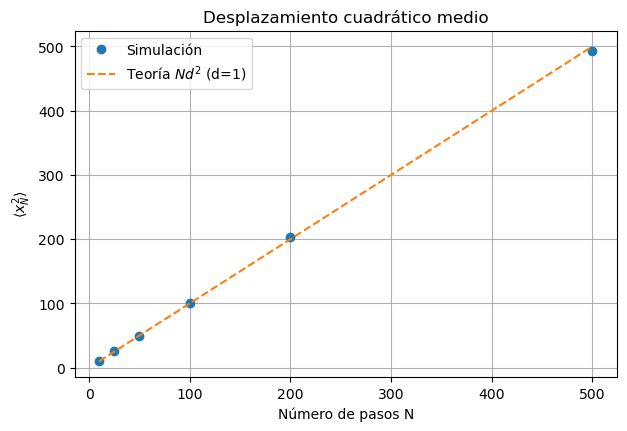

In [9]:
Ns = np.array([10, 25, 50, 100, 200, 500])
M = 5_000
msd_estimado = []
for n in Ns:
    posiciones_finales = simular_caminatas(M, int(n), d=1, semilla=100+n)[:, -1]
    msd_estimado.append(np.mean(posiciones_finales**2))

fig, ax = plt.subplots()
ax.plot(Ns, msd_estimado, "o", label="Simulación")
ax.plot(Ns, Ns, "--", label=r"Teoría $Nd^2$ (d=1)")
ax.set(xlabel="Número de pasos N", ylabel=r"$\langle x_N^2\rangle$", title="Desplazamiento cuadrático medio")
ax.legend(); plt.show()

## 6. Extensión: caminata aleatoria en dos dimensiones
En cada paso se elige una de cuatro direcciones cardinales, con probabilidad 1/4. Se puede estudiar la distribución de posiciones finales y el desplazamiento radial cuadrático medio.

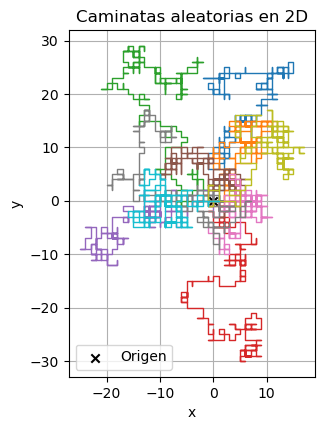

MSD radial simulado: 301.924
MSD radial teórico: 300


In [10]:
def simular_caminatas_2d(n_particulas, n_pasos, d=1.0, semilla=2026):
    generador = np.random.default_rng(semilla)
    # Direcciones: derecha, izquierda, arriba, abajo
    direcciones = np.array([[d,0], [-d,0], [0,d], [0,-d]])
    indices = generador.integers(0, 4, size=(n_particulas, n_pasos))
    pasos = direcciones[indices]
    posiciones = np.concatenate([np.zeros((n_particulas, 1, 2)), np.cumsum(pasos, axis=1)], axis=1)
    return posiciones

pos2 = simular_caminatas_2d(1_000, 300, semilla=17)
fig, ax = plt.subplots()
for i in range(10):
    ax.plot(pos2[i, :, 0], pos2[i, :, 1], lw=1)
ax.scatter([0], [0], marker="x", color="black", label="Origen")
ax.set(xlabel="x", ylabel="y", title="Caminatas aleatorias en 2D", aspect="equal")
ax.legend(); plt.show()

r2_final = np.sum(pos2[:, -1, :]**2, axis=1)
print("MSD radial simulado:", r2_final.mean())
print("MSD radial teórico:", 300)

## 7. Ejercicios para realizar en casa
### Ejercicio 1. Integración Monte Carlo
Estime $\int_0^2 (1+x^2)^{-1}\,dx$, cuyo valor exacto es $\arctan(2)$. Use $N=10^2,10^3,10^4,10^5$, grafique el error absoluto y explique por qué no necesariamente disminuye monótonamente.

### Ejercicio 2. Caminata aleatoria
Simule al menos 500 partículas para $N=10,50,100,500$ pasos. Compare la media del desplazamiento y el desplazamiento cuadrático medio con las predicciones $0$ y $N$ (para $d=1$). Incluya gráficas y una interpretación física.